# 连续特征上的 Token-Level Sparse MoE：Specialization、Balance 与消融实验

## 0. 实验设定（运行前先读这一节）

本实验是一个**token-level 回归任务**，不使用 Attention、语言建模语料或 token ID。一个样本中的每个位置都是相互独立的连续 token；序列维度 $$L$$ 仅用于模拟 Transformer 中的 token batch 形状。

| 项目 | 固定设定 | 作用 |
| --- | --- | --- |
| 输入形状 | `[B, L, D] = [256, 16, 8]` | 每步共有 $$256\times16=4096$$ 个连续 token |
| 隐藏模式数 | $$G=6$$ | 数据生成器的 group 标签；模型不可见 |
| Expert 数 / 路由 | $$N=6$$，Noisy Top-$$K=2$$ | 每个 token 仅保留两个非零 gate |
| 连续 cluster | 六边形中心，默认 $$\sigma=0.70$$ | 前两个特征维度可区分但存在重叠 |
| 每组任务 | 独立的 $$w_g,b_g$$ | 同一 group 应学习同一个局部回归规律 |
| Expert 容量 | $$8\rightarrow16\rightarrow8$$ MLP | 限制单 Expert 的容量，鼓励分工 |
| 训练 | AdamW，1500 steps，学习率 $$2\times10^{-3}$$ | 所有训练输入在线重新采样 |
| 评估 | 1024 条全新序列 | 检查泛化，而不是记住训练样本 |

### 模型究竟能看见什么？

模型只接收连续特征：

$$
x_{b,t}\in\mathbb R^8
$$

它**看不见**以下信息：

$$
z_{b,t}
$$

$$
\mu_{z_{b,t}}
$$

$$
w_{z_{b,t}},b_{z_{b,t}}
$$

其中 $$z_{b,t}$$ 只在生成 target 和训练后计算 `Group → Expert` 统计时使用。也就是说，若 Router 与 group 有相关性，只能来自它从 $$x$$ 的统计模式中自行学到的表征。

### 数据怎样生成？

对每个位置，先均匀抽取一个隐藏 group：

$$
z_{b,t}\sim\mathrm{Uniform}\{0,1,\ldots,5\}
$$

再从对应高斯 cluster 抽取一个新向量：

$$
x_{b,t}\mid z_{b,t}=g
\sim\mathcal N(\mu_g,0.70^2I)
$$

最后按该 group 的固定线性规律生成回归目标：

$$
y_{b,t}=w_g^\top x_{b,t}+b_g
$$

因此每个训练 step 都是新的 $$x$$，但同一隐藏 group 的函数规律保持一致。

### 三个对照实验到底差在哪里？

| 名称 | 模型 | 优化目标 | 想验证的事情 |
| --- | --- | --- | --- |
| Full MoE | 6 Expert、Top-2 Router | $$L_{task}+0.05L_{importance}+0.05L_{load}$$ | 能否同时得到分工和整体均衡 |
| No-Balance MoE | 与 Full MoE 的结构、初始化和训练步数一致 | $$L_{task}$$ | 没有辅助损失时，路由会否更偏斜或 collapse |
| Dense FFN | 单个 $$8\rightarrow96\rightarrow1$$ FFN | $$L_{task}$$ | 条件计算是否相对单网络带来不同的泛化/容量行为 |

Dense baseline 的中间宽度 $$96=6\times16$$，使其 FFN 容量接近六个 Expert 的总隐藏宽度；它没有 Router，因此不会产生 Expert specialization 指标。

---

## 1. 实验问题

本 notebook 要验证的不是“Expert 编号能否恰好等于人为 group 编号”，而是下面的机制能否在端到端训练中自发出现：

$$
\boxed{
\text{连续 token 特征}
\rightarrow
\text{Router 识别潜在模式}
\rightarrow
\text{Top-}K\text{ Expert}
\rightarrow
\text{局部 specialization + 全局 load balance}
}
$$

旧的离散 token 实验可借助 `token ID → embedding → 输出` 记忆答案。本实验每一步重新采样连续输入，模型必须从输入模式中泛化；隐藏 group 标签不输入模型，只用于生成目标和最后评估。

---

## 2. 数据与任务

每个 token 有隐藏类别：

$$
z_{b,t}\in\{0,1,\ldots,G-1\},\qquad G=6
$$

连续特征的条件分布为：

$$
x_{b,t}\mid z_{b,t}=g
\sim \mathcal N(\mu_g,\sigma^2I),
\qquad x_{b,t}\in\mathbb R^D,
\qquad D=8
$$

六个中心 $$\mu_g$$ 在前两个维度形成有适度重叠的六边形。每一个 group 对应不同的线性规律：

$$
\boxed{
y_{b,t}=w_{z_{b,t}}^\top x_{b,t}+b_{z_{b,t}}\ }
$$

同一个具体 $$x$$ 不会在训练中重复出现。因此模型不能查表，只能学习“输入属于何种模式”以及“该模式要使用什么函数”。

---

## 3. Sparse MoE 数学结构

每个 Expert 是独立的两层 MLP：

$$
E_i(h)=W_{i,2}\,\mathrm{GELU}(W_{i,1}h+b_{i,1})+b_{i,2}
$$

Router 对 token 表示 $$h$$ 输出 clean logits 与噪声尺度：

$$
\mu(h)=W_gh+b_g
$$

$$
\sigma(h)=\mathrm{Softplus}(W_{noise}h+b_{noise})+\epsilon
$$

训练时使用 Noisy Top-K：

$$
H(h)=\mu(h)+\sigma(h)\odot\varepsilon,
\qquad \varepsilon\sim\mathcal N(0,I)
$$

$$
\mathcal T(h)=\operatorname{TopK}(H(h),K),
qquad K=2
$$

$$
g_i(h)=
\begin{cases}
\displaystyle\frac{\exp(H_i(h))}{\sum_{j\in\mathcal T(h)}\exp(H_j(h))}, & i\in\mathcal T(h)\\
0, & \text{otherwise}
\end{cases}
$$

$$
\boxed{
\mathrm{MoE}(h)=\sum_{i=1}^Ng_i(h)E_i(h)
}
$$

为突出数学过程，教学代码会计算全部 Expert 输出后再由稀疏 gate 合并。真正的生产 MoE 会执行 token dispatch，仅计算被选中的 Top-K Expert。

---

## 4. 损失函数

任务为标量回归：

$$
\mathcal L_{task}=
\frac1{BL}\sum_{b,t}(\hat y_{b,t}-y_{b,t})^2
$$

Importance 衡量所有 token 分配给 Expert $$i$$ 的总 gate mass：

$$
I_i=\sum_{b,t}g_i(x_{b,t})
$$

$$
\mathcal L_{importance}=
\mathrm{CV}^2([I_1,\ldots,I_N]),
\qquad
\mathrm{CV}^2(v)=\frac{\mathrm{Var}(v)}{\mathrm{Mean}(v)^2+\epsilon}
$$

Hard Top-K 计数不可导，因此 smooth load 用被选入 Top-K 的概率近似：

$$
P(i\in\mathcal T(x))=
\Phi\left(\frac{\mu_i-T_i}{\sigma_i}\right)
$$

$$
L_i=\sum_{b,t}P(i\in\mathcal T(x_{b,t})),
qquad
\mathcal L_{load}=\mathrm{CV}^2([L_1,\ldots,L_N])
$$

$$
\boxed{
\mathcal L=
\mathcal L_{task}
+\lambda_I\mathcal L_{importance}
+\lambda_L\mathcal L_{load}
}
$$

本实现用批量 `topk`、`scatter`、`where`、`erf` 计算 smooth load，不再逐 token / 逐 Expert 执行 Python 循环。

---

## 5. 本次消融设计

依次训练三种模型，比较新采样数据上的 MSE 与路由统计：

| 实验 | 目的 |
| --- | --- |
| Full MoE | 同时使用 task、importance、smooth-load loss |
| No-Balance MoE | 将 $$\lambda_I=\lambda_L=0$$，观察没有防 collapse 约束时的路由 |
| Dense FFN | 用参数量近似匹配的单个 FFN 替代 MoE，作为非条件计算 baseline |

额外报告 hidden group 与 Expert 的互信息。令 $$P(g,e)$$ 是 group 条件平均 gate mass 形成的联合分布：

$$
I(G;E)=\sum_{g,e}P(g,e)
\log\frac{P(g,e)}{P(g)P(e)}
$$

若所有 group 都把质量交给同一个 Expert，或每个 group 都均匀路由，互信息都会较低；高互信息同时配合较均衡的 overall usage，才是我们想看到的 specialization 而非 collapse。

运行下方代码时，`groups` 只出现在数据生成、评估和可视化步骤，绝不会输入模型。

In [17]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)

# ============================================================
# 1. 配置
# ============================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

NUM_GROUPS = 6
NUM_EXPERTS = 6
TOP_K = 2

SEQ_LEN = 16
BATCH_SIZE = 256
EVAL_BATCH_SIZE = 1024

D_MODEL = 8
D_FF = 16
DENSE_D_FF = NUM_EXPERTS * D_FF  # Dense baseline 的 FFN 宽度，近似匹配总 Expert 容量

TRAIN_STEPS = 1500
LEARNING_RATE = 2e-3
LOG_EVERY = 100

FEATURE_STD = 0.70
LAMBDA_IMPORTANCE = 0.05
LAMBDA_LOAD = 0.05

# 可选鲁棒性实验：默认关闭，以便先快速运行核心三组消融。
RUN_OVERLAP_SWEEP = False
OVERLAP_STDS = [0.50, 0.70, 1.00, 1.30]
SWEEP_STEPS = 700


# ============================================================
# 2. 连续数据：隐藏 group 不输入模型
# ============================================================

GROUP_CENTERS = torch.tensor(
    [
        [ 2.4,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0],
        [ 1.2,  2.1,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0],
        [-1.2,  2.1,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0],
        [-2.4,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0],
        [-1.2, -2.1,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0],
        [ 1.2, -2.1,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0],
    ],
    dtype=torch.float32,
    device=DEVICE
)

GROUP_WEIGHTS = torch.tensor(
    [
        [ 1.4, -0.8,  0.6,  0.0,  0.3, -0.2,  0.0,  0.1],
        [-1.1,  1.3,  0.0,  0.7, -0.4,  0.2,  0.3,  0.0],
        [ 0.5,  1.6, -1.0,  0.2,  0.0,  0.4, -0.3,  0.2],
        [-1.5, -0.6,  0.5, -0.8,  0.3,  0.0,  0.2, -0.4],
        [ 0.8, -1.4,  0.2,  0.5, -0.7,  0.3,  0.1,  0.0],
        [ 1.0,  0.4, -0.6,  0.0,  0.5, -0.8,  0.2,  0.3],
    ],
    dtype=torch.float32,
    device=DEVICE
)

GROUP_BIASES = torch.tensor(
    [0.4, -0.6, 0.2, -0.3, 0.7, -0.4],
    dtype=torch.float32,
    device=DEVICE
)


def make_batch(batch_size, seq_len, feature_std=FEATURE_STD):
    groups = torch.randint(
        0, NUM_GROUPS, (batch_size, seq_len), device=DEVICE
    )
    features = (
        GROUP_CENTERS[groups]
        + feature_std * torch.randn(
            batch_size, seq_len, D_MODEL, device=DEVICE
        )
    )
    targets = (
        (features * GROUP_WEIGHTS[groups]).sum(dim=-1, keepdim=True)
        + GROUP_BIASES[groups].unsqueeze(-1)
    )
    return features, groups, targets


# ============================================================
# 3. 模型
# ============================================================

class Expert(nn.Module):

    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(D_MODEL, D_FF),
            nn.GELU(),
            nn.Linear(D_FF, D_MODEL)
        )

    def forward(self, x):
        return self.net(x)


class NoisyTopKRouter(nn.Module):

    def __init__(self):
        super().__init__()
        self.gate = nn.Linear(D_MODEL, NUM_EXPERTS)
        self.noise = nn.Linear(D_MODEL, NUM_EXPERTS)

    def forward(self, x):
        mu = self.gate(x)
        sigma = F.softplus(self.noise(x)) + 1e-4
        noisy_logits = (
            mu + sigma * torch.randn_like(mu)
            if self.training else mu
        )
        topk_values, topk_indices = torch.topk(
            noisy_logits, TOP_K, dim=-1
        )
        topk_weights = F.softmax(topk_values, dim=-1)
        gates = torch.zeros_like(noisy_logits)
        gates.scatter_(dim=-1, index=topk_indices, src=topk_weights)
        return gates, mu, sigma, noisy_logits, topk_indices


class SparseMoE(nn.Module):

    def __init__(self):
        super().__init__()
        self.router = NoisyTopKRouter()
        self.experts = nn.ModuleList([Expert() for _ in range(NUM_EXPERTS)])

    def forward(self, x):
        gates, mu, sigma, noisy_logits, topk_indices = self.router(x)
        # 教学版：所有 Expert 都 forward；真实 sparse dispatch 只计算 Top-K。
        expert_outputs = torch.stack(
            [expert(x) for expert in self.experts], dim=2
        )
        output = (gates.unsqueeze(-1) * expert_outputs).sum(dim=2)
        return output, gates, mu, sigma, noisy_logits, topk_indices


class ContinuousTokenMoEModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.input_norm = nn.LayerNorm(D_MODEL)
        self.moe = SparseMoE()
        self.output_head = nn.Linear(D_MODEL, 1)

    def forward(self, features):
        x = self.input_norm(features)
        x, gates, mu, sigma, noisy_logits, topk_indices = self.moe(x)
        predictions = self.output_head(x)
        return predictions, gates, mu, sigma, noisy_logits, topk_indices


class DenseFFNBaseline(nn.Module):

    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(D_MODEL),
            nn.Linear(D_MODEL, DENSE_D_FF),
            nn.GELU(),
            nn.Linear(DENSE_D_FF, 1)
        )

    def forward(self, features):
        return self.net(features)


Using device: cpu


In [18]:
# ============================================================
# 4. 向量化 load loss、路由统计与训练函数
# ============================================================

def coefficient_of_variation_squared(values):
    return values.var(unbiased=False) / (values.mean() ** 2 + 1e-8)


def compute_importance_loss(gates):
    importance = gates.sum(dim=(0, 1))
    return coefficient_of_variation_squared(importance), importance


def compute_hard_load(topk_indices):
    return torch.bincount(
        topk_indices.reshape(-1), minlength=NUM_EXPERTS
    )


def compute_smooth_load_loss(mu, sigma, noisy_logits):
    """Noisy Top-K expected load；没有逐 token / Expert 的 Python 循环。"""

    _, _, num_experts = mu.shape
    if TOP_K >= num_experts:
        raise ValueError("TOP_K must be smaller than NUM_EXPERTS")

    mu_flat = mu.reshape(-1, num_experts)
    sigma_flat = sigma.reshape(-1, num_experts)
    noisy_flat = noisy_logits.reshape(-1, num_experts)

    # i 在原始 Top-K：排除 i 后阈值为第 K+1 大；否则仍为第 K 大。
    topk_plus_one = torch.topk(noisy_flat, k=TOP_K + 1, dim=-1)
    kth_threshold = topk_plus_one.values[:, TOP_K - 1].unsqueeze(-1)
    kplus1_threshold = topk_plus_one.values[:, TOP_K].unsqueeze(-1)

    in_topk = torch.zeros_like(noisy_flat, dtype=torch.bool)
    in_topk.scatter_(
        dim=-1,
        index=topk_plus_one.indices[:, :TOP_K],
        value=True
    )
    threshold = torch.where(in_topk, kplus1_threshold, kth_threshold)

    z = (mu_flat - threshold) / sigma_flat
    probabilities = 0.5 * (1.0 + torch.erf(z / (2.0 ** 0.5)))
    smooth_load = probabilities.sum(dim=0)
    return (
        coefficient_of_variation_squared(smooth_load),
        smooth_load,
        probabilities
    )


def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def train_moe(name, lambda_importance, lambda_load, steps, feature_std, seed):
    set_seed(seed)
    model = ContinuousTokenMoEModel().to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
    )
    history = {"step": [], "mse": [], "importance_cv2": [], "load_cv2": []}

    for step in range(steps):
        model.train()
        features, _, targets = make_batch(BATCH_SIZE, SEQ_LEN, feature_std)
        predictions, gates, mu, sigma, noisy_logits, _ = model(features)

        task_loss = F.mse_loss(predictions, targets)
        importance_loss, _ = compute_importance_loss(gates)

        if lambda_load > 0:
            load_loss, _, _ = compute_smooth_load_loss(mu, sigma, noisy_logits)
        else:
            load_loss = torch.zeros((), device=DEVICE)

        total_loss = (
            task_loss
            + lambda_importance * importance_loss
            + lambda_load * load_loss
        )

        optimizer.zero_grad(set_to_none=True)
        total_loss.backward()
        optimizer.step()

        if step % LOG_EVERY == 0 or step == steps - 1:
            history["step"].append(step)
            history["mse"].append(task_loss.item())
            history["importance_cv2"].append(importance_loss.item())
            history["load_cv2"].append(load_loss.item())
            print(
                f"{name:14s} step={step:4d} | "
                f"mse={task_loss.item():.4f} | "
                f"importance={importance_loss.item():.4f} | "
                f"load={load_loss.item():.4f}"
            )

    return model, history


def train_dense(name, steps, feature_std, seed):
    set_seed(seed)
    model = DenseFFNBaseline().to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
    )
    history = {"step": [], "mse": []}

    for step in range(steps):
        model.train()
        features, _, targets = make_batch(BATCH_SIZE, SEQ_LEN, feature_std)
        predictions = model(features)
        loss = F.mse_loss(predictions, targets)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if step % LOG_EVERY == 0 or step == steps - 1:
            history["step"].append(step)
            history["mse"].append(loss.item())
            print(f"{name:14s} step={step:4d} | mse={loss.item():.4f}")

    return model, history


def evaluate_moe(model, feature_std, seed=2026):
    set_seed(seed)
    model.eval()
    features, groups, targets = make_batch(EVAL_BATCH_SIZE, SEQ_LEN, feature_std)

    with torch.no_grad():
        predictions, gates, mu, sigma, noisy_logits, topk_indices = model(features)
        mse = F.mse_loss(predictions, targets).item()
        _, smooth_load, _ = compute_smooth_load_loss(mu, sigma, noisy_logits)

    flat_groups = groups.reshape(-1)
    flat_gates = gates.reshape(-1, NUM_EXPERTS)
    group_onehot = F.one_hot(flat_groups, NUM_GROUPS).float()
    group_counts = group_onehot.sum(dim=0)
    group_expert = group_onehot.T @ flat_gates / group_counts.unsqueeze(-1)

    # P(group, expert) 由 gate mass 形成；因此总和为 1。
    joint = group_onehot.T @ flat_gates / flat_groups.numel()
    p_group = joint.sum(dim=1, keepdim=True)
    p_expert = joint.sum(dim=0, keepdim=True)
    mutual_information = (
        joint * (
            (joint + 1e-8).log()
            - (p_group @ p_expert + 1e-8).log()
        )
    ).sum().item()

    group_entropy = -(
        group_expert.clamp_min(1e-8)
        * group_expert.clamp_min(1e-8).log()
    ).sum(dim=1)
    specialization = 1.0 - group_entropy / torch.log(
        torch.tensor(float(NUM_EXPERTS), device=DEVICE)
    )

    hard_load = compute_hard_load(topk_indices).float()
    return {
        "mse": mse,
        "group_expert": group_expert,
        "entropy": group_entropy,
        "specialization": specialization,
        "mutual_information": mutual_information,
        "overall_gate_mass": flat_gates.mean(dim=0),
        "hard_load_share": hard_load / hard_load.sum(),
        "smooth_load_share": smooth_load / smooth_load.sum(),
    }


def evaluate_dense(model, feature_std, seed=2026):
    set_seed(seed)
    model.eval()
    features, _, targets = make_batch(EVAL_BATCH_SIZE, SEQ_LEN, feature_std)
    with torch.no_grad():
        return F.mse_loss(model(features), targets).item()


In [19]:
# ============================================================
# 5. 运行三组核心实验
# ============================================================

full_moe, full_history = train_moe(
    name="Full MoE",
    lambda_importance=LAMBDA_IMPORTANCE,
    lambda_load=LAMBDA_LOAD,
    steps=TRAIN_STEPS,
    feature_std=FEATURE_STD,
    seed=42
)

no_balance_moe, no_balance_history = train_moe(
    name="No-Balance MoE",
    lambda_importance=0.0,
    lambda_load=0.0,
    steps=TRAIN_STEPS,
    feature_std=FEATURE_STD,
    seed=42
)

dense_baseline, dense_history = train_dense(
    name="Dense FFN",
    steps=TRAIN_STEPS,
    feature_std=FEATURE_STD,
    seed=42
)


Full MoE       step=   0 | mse=9.5138 | importance=0.1293 | load=0.1070
Full MoE       step= 100 | mse=2.3805 | importance=0.1383 | load=0.0925
Full MoE       step= 200 | mse=1.6971 | importance=0.2196 | load=0.1127
Full MoE       step= 300 | mse=1.5028 | importance=0.2529 | load=0.0742
Full MoE       step= 400 | mse=1.3405 | importance=0.2555 | load=0.0430
Full MoE       step= 500 | mse=1.4220 | importance=0.2191 | load=0.0180
Full MoE       step= 600 | mse=1.2952 | importance=0.1572 | load=0.0080
Full MoE       step= 700 | mse=1.2597 | importance=0.1063 | load=0.0047
Full MoE       step= 800 | mse=1.1428 | importance=0.0849 | load=0.0065
Full MoE       step= 900 | mse=1.3203 | importance=0.0654 | load=0.0063
Full MoE       step=1000 | mse=1.2648 | importance=0.0490 | load=0.0089
Full MoE       step=1100 | mse=1.2557 | importance=0.0428 | load=0.0101
Full MoE       step=1200 | mse=1.3194 | importance=0.0414 | load=0.0096
Full MoE       step=1300 | mse=1.2907 | importance=0.0313 | load

In [20]:
# ============================================================
# 6. 新样本上的泛化与消融汇总
# ============================================================

full_stats = evaluate_moe(full_moe, FEATURE_STD)
no_balance_stats = evaluate_moe(no_balance_moe, FEATURE_STD)
dense_mse = evaluate_dense(dense_baseline, FEATURE_STD)

print("\nGENERALIZATION / ABLATION SUMMARY\n")
print(f"{'Model':<18} {'MSE':>10} {'MI(G;E)':>12} {'Mean specialization':>22}")
print("-" * 68)
print(
    f"{'Full MoE':<18} {full_stats['mse']:>10.6f} "
    f"{full_stats['mutual_information']:>12.4f} "
    f"{full_stats['specialization'].mean().item():>22.4f}"
)
print(
    f"{'No-Balance MoE':<18} {no_balance_stats['mse']:>10.6f} "
    f"{no_balance_stats['mutual_information']:>12.4f} "
    f"{no_balance_stats['specialization'].mean().item():>22.4f}"
)
print(f"{'Dense FFN':<18} {dense_mse:>10.6f} {'N/A':>12} {'N/A':>22}")

print("\nFull MoE overall gate mass:")
print([round(v, 3) for v in full_stats['overall_gate_mass'].detach().cpu().tolist()])
print("No-Balance MoE overall gate mass:")
print([round(v, 3) for v in no_balance_stats['overall_gate_mass'].detach().cpu().tolist()])



GENERALIZATION / ABLATION SUMMARY

Model                     MSE      MI(G;E)    Mean specialization
--------------------------------------------------------------------
Full MoE             1.252059       0.9186                 0.5189
No-Balance MoE       1.246200       0.8727                 0.6912
Dense FFN            1.268582          N/A                    N/A

Full MoE overall gate mass:
[0.192, 0.172, 0.185, 0.186, 0.127, 0.137]
No-Balance MoE overall gate mass:
[0.206, 0.266, 0.207, 0.308, 0.0, 0.014]


In [21]:
# ============================================================
# 7. Full MoE 的 Group -> Expert specialization
# ============================================================

print("\nFULL MOE: EXPERT SPECIALIZATION (average gate mass)\n")
for group in range(NUM_GROUPS):
    values = full_stats["group_expert"][group]
    favorite = values.argmax().item()
    entropy = full_stats["entropy"][group].item()
    score = full_stats["specialization"][group].item()
    print(
        f"Group {group}: "
        f"{[round(v, 3) for v in values.detach().cpu().tolist()]} "
        f"-> favorite E{favorite}, entropy={entropy:.3f}, S={score:.3f}"
    )

print(f"\nMutual information I(Group; Expert) = {full_stats['mutual_information']:.4f}")
print("Hard-load share:  ", [round(v, 3) for v in full_stats['hard_load_share'].detach().cpu().tolist()])
print("Smooth-load share:", [round(v, 3) for v in full_stats['smooth_load_share'].detach().cpu().tolist()])



FULL MOE: EXPERT SPECIALIZATION (average gate mass)

Group 0: [0.415, 0.47, 0.004, 0.0, 0.111, 0.0] -> favorite E1, entropy=0.990, S=0.448
Group 1: [0.672, 0.012, 0.315, 0.0, 0.0, 0.001] -> favorite E0, entropy=0.691, S=0.614
Group 2: [0.072, 0.0, 0.738, 0.024, 0.0, 0.165] -> favorite E2, entropy=0.804, S=0.551
Group 3: [0.0, 0.0, 0.051, 0.489, 0.0, 0.459] -> favorite E3, entropy=0.864, S=0.518
Group 4: [0.0, 0.037, 0.0, 0.598, 0.165, 0.199] -> favorite E3, entropy=1.051, S=0.414
Group 5: [0.002, 0.507, 0.0, 0.012, 0.478, 0.001] -> favorite E1, entropy=0.773, S=0.569

Mutual information I(Group; Expert) = 0.9186
Hard-load share:   [0.171, 0.176, 0.167, 0.156, 0.14, 0.189]
Smooth-load share: [0.171, 0.175, 0.168, 0.156, 0.14, 0.189]


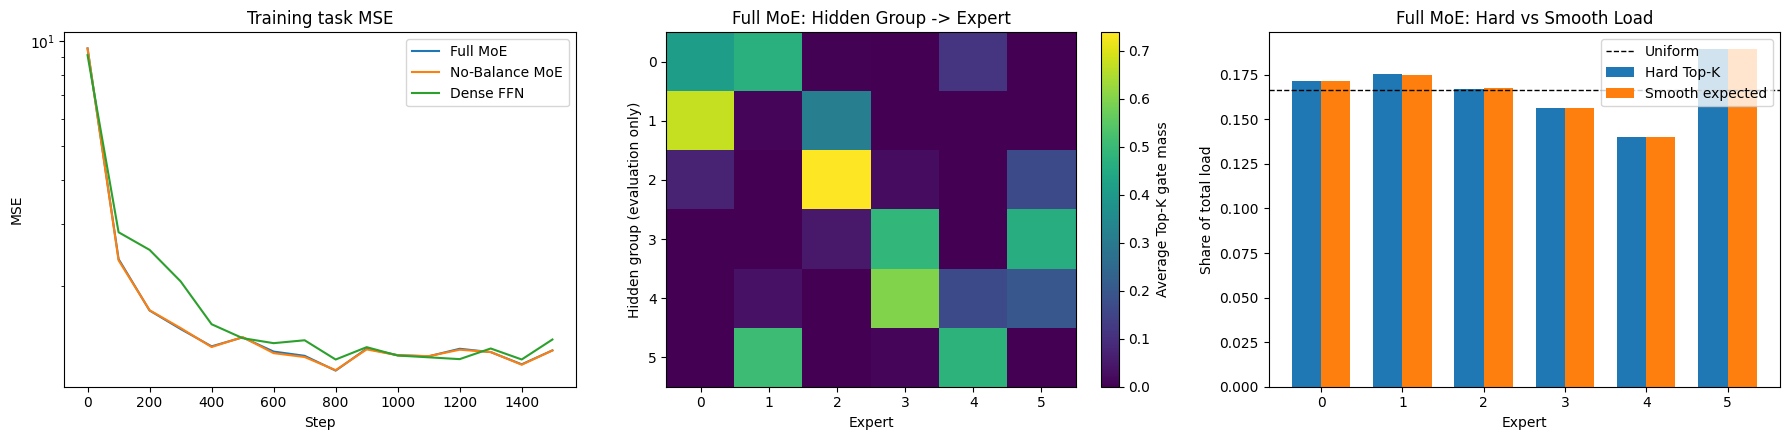

In [22]:
# ============================================================
# 8. 可视化：训练、specialization、hard vs smooth load
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].plot(full_history["step"], full_history["mse"], label="Full MoE")
axes[0].plot(no_balance_history["step"], no_balance_history["mse"], label="No-Balance MoE")
axes[0].plot(dense_history["step"], dense_history["mse"], label="Dense FFN")
axes[0].set_title("Training task MSE")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("MSE")
axes[0].set_yscale("log")
axes[0].legend()

image = axes[1].imshow(
    full_stats["group_expert"].detach().cpu().numpy(),
    aspect="auto",
    vmin=0.0
)
axes[1].set_title("Full MoE: Hidden Group -> Expert")
axes[1].set_xlabel("Expert")
axes[1].set_ylabel("Hidden group (evaluation only)")
axes[1].set_xticks(range(NUM_EXPERTS))
axes[1].set_yticks(range(NUM_GROUPS))
fig.colorbar(image, ax=axes[1], label="Average Top-K gate mass")

expert_ids = torch.arange(NUM_EXPERTS).cpu().numpy()
axes[2].bar(expert_ids - 0.18, full_stats["hard_load_share"].detach().cpu().numpy(), width=0.36, label="Hard Top-K")
axes[2].bar(expert_ids + 0.18, full_stats["smooth_load_share"].detach().cpu().numpy(), width=0.36, label="Smooth expected")
axes[2].axhline(1 / NUM_EXPERTS, color="black", linestyle="--", linewidth=1, label="Uniform")
axes[2].set_title("Full MoE: Hard vs Smooth Load")
axes[2].set_xlabel("Expert")
axes[2].set_ylabel("Share of total load")
axes[2].set_xticks(expert_ids)
axes[2].legend()

plt.tight_layout()
plt.show()


In [23]:
# ============================================================
# 9. 可选：增加 cluster overlap 的鲁棒性扫描
#
# 设 RUN_OVERLAP_SWEEP = True 后再运行本单元。
# ============================================================

if RUN_OVERLAP_SWEEP:
    sweep_results = []

    for index, std in enumerate(OVERLAP_STDS):
        model, _ = train_moe(
            name=f"Sweep std={std:.2f}",
            lambda_importance=LAMBDA_IMPORTANCE,
            lambda_load=LAMBDA_LOAD,
            steps=SWEEP_STEPS,
            feature_std=std,
            seed=100 + index
        )
        stats = evaluate_moe(model, std, seed=300 + index)
        sweep_results.append(
            {
                "std": std,
                "mse": stats["mse"],
                "mi": stats["mutual_information"],
                "specialization": stats["specialization"].mean().item(),
            }
        )

    print("\nOVERLAP ROBUSTNESS SWEEP\n")
    for result in sweep_results:
        print(
            f"std={result['std']:.2f} | mse={result['mse']:.5f} | "
            f"I(G;E)={result['mi']:.4f} | "
            f"mean S={result['specialization']:.4f}"
        )

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    stds = [result["std"] for result in sweep_results]
    axes[0].plot(stds, [result["mse"] for result in sweep_results], marker="o")
    axes[0].set_xlabel("Feature std (cluster overlap increases)")
    axes[0].set_ylabel("Generalization MSE")
    axes[0].set_title("Task robustness")
    axes[1].plot(stds, [result["mi"] for result in sweep_results], marker="o", label="I(Group; Expert)")
    axes[1].plot(stds, [result["specialization"] for result in sweep_results], marker="s", label="Mean specialization")
    axes[1].set_xlabel("Feature std")
    axes[1].set_title("Routing robustness")
    axes[1].legend()
    plt.tight_layout()
    plt.show()
else:
    print("Overlap sweep is disabled. Set RUN_OVERLAP_SWEEP = True to run it.")


Overlap sweep is disabled. Set RUN_OVERLAP_SWEEP = True to run it.


---

# 10. 如何判断实验结果

## A. Full MoE 的局部 specialization

`Group -> Expert` 热力图的第 $$g$$ 行为：

$$
\bar g_{g,i}=
\frac1{|\{(b,t):z_{b,t}=g\}|}
\sum_{(b,t):z_{b,t}=g}g_i(x_{b,t})
$$

每行之和为 1；它表示平均 gate mass，而非硬路由 token 比例。使用 Top-2 时，一个 group 通常会有主 Expert 与次 Expert，例如：

$$
G_1\rightarrow E_0+E_2
$$

这是组合式 specialization，不要求一 group 对一 Expert，也不要求亮点沿热力图对角线出现。

每行同时报告 entropy：

$$
H_g=-\sum_i\bar g_{g,i}\log\bar g_{g,i}
$$

以及归一化 specialization：

$$
S_g=1-\frac{H_g}{\log N}
$$

均匀路由时 $$S_g\approx0$$；分布越集中，$$S_g$$ 越接近 1。

## B. specialization 与 collapse 的区别

只看 entropy 不够：若所有 group 都集中到同一个 Expert，entropy 也会低，但那是 collapse。因此还要同时看：

$$
I(G;E)
$$

和 `overall gate mass`。理想图景是：对单个 group，$$P(E\mid G)$$ 明显不均匀；将所有 group 混合后，$$P(E)$$ 仍相对均衡。这正是：

$$
\boxed{\text{local specialization} + \text{global load balance}}
$$

的含义。

## C. Full MoE 与 No-Balance MoE

No-Balance 版本没有：

$$
\lambda_I\mathcal L_{importance}
$$

和：

$$
\lambda_L\mathcal L_{load}
$$

因此它可能获得相近的 MSE，却出现更偏斜的 overall gate mass、hard-load share 或 smooth-load share。具体是否发生完全 collapse 受随机种子和任务难度影响；“更不均衡”的趋势才是消融实验的重点。

## D. Hard Load 与 Smooth Load

图中的 Hard Top-K 是：

$$
\sum_x\mathbf 1[i\in\mathrm{TopK}(x)]
$$

Smooth expected load 是：

$$
\sum_xP(i\in\mathrm{TopK}\mid x)
$$

两组柱状分布不必逐 Expert 完全相同，因为 smooth load 是带噪声路由下的可导期望，但总体趋势应接近。它说明 2017 Noisy Top-K MoE 为什么能够通过一个连续 surrogate 优化离散的 Expert 选择。

## E. overlap 扫描

开启可选实验后，随着 $$\sigma$$ 增大，cluster 重叠增加。通常 MSE 会变差，$$I(G;E)$$ 与 $$S_g$$ 也可能下降；这衡量 Router 的 specialization 是否只依赖极易分开的 cluster。

运行顺序：按从上到下顺序执行全部代码单元。若要做 overlap 扫描，将 `RUN_OVERLAP_SWEEP` 改为 `True`，再运行“可选：增加 cluster overlap 的鲁棒性扫描”代码单元。
